<h1 style="color:#295c6b;font-weight:600;">Time series prediction using Support Vector Regressor</h1>

**SVR** stands for SVM: Support Vector Machine for regression (or Support Vector Regressor).<br/>
> **When to use SVM?** When the time series data have *non-linearity*, SVM is better than ARIMA in time-series forecasting.

<h3 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">SVR in the context of time series</h3>

| METHOD | DESCRIPTION |
|---|---|
| `Regression` | Supervised learning technique to predict continuous values. |
| `SVM` | Supervised machine learning model used for classification, regression and outliers detection.<br/>A Kernel function is used to transform the dataset to a space of higher number of dimensions. |
| `SVR` | A type of SVM, to find the best fit line/hyperplane that has the max number of data points. |

In this notebook, we demonstrate how to:

- prepare 2D time series data for training an SVM regressor model
- implement SVR using RBF kernel
- evaluate the model using plots and MAPE

<h3 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Importing Modules</h3>

In [1]:
import sys

sys.path.append("../../")

In [92]:
from logging import warning
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt
import math

from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler
from common.utils import load_data, mape

warnings.filterwarnings("ignore", category=UserWarning)

<h3 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Preparing Data</h3>

<h5 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Load Data</h5>

In [4]:
energy = load_data("../../data")[["load"]]
energy.tail(5)

,load
2014-12-31 19:00:00,4012.0
2014-12-31 20:00:00,3856.0
2014-12-31 21:00:00,3671.0
2014-12-31 22:00:00,3499.0
2014-12-31 23:00:00,3345.0


<h5 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Plot the Data</h5>

Plot energy data from 2012 Jan, to 2014 Dec:

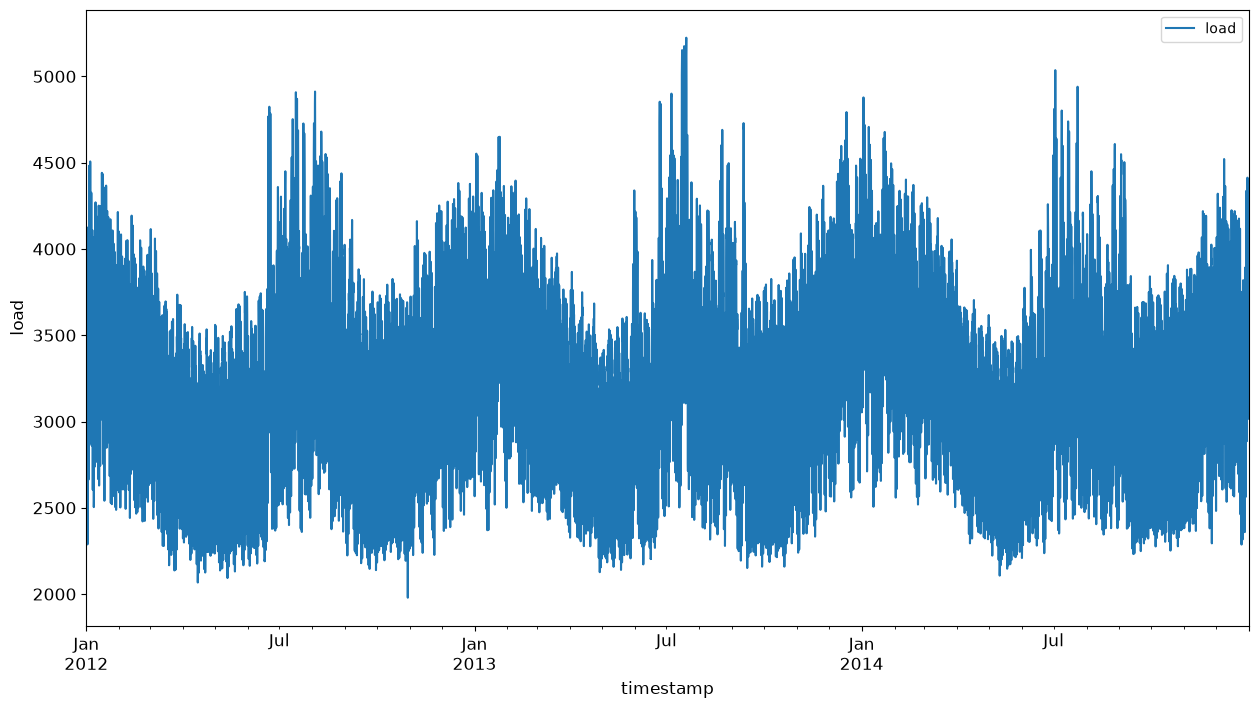

In [5]:
energy.plot(y="load", subplots=True, figsize=(15, 8), fontsize=12)
plt.xlabel("timestamp", fontsize=12)
plt.ylabel("load", fontsize=12)
plt.show()

<h5 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Create Training and Testing Datasets</h5>

Ensure that the test set covers a later period in time than the training set, to ensure the model does not gain information from future time periods (overfitting).

> **Train set** : 1-09-2014 to 31-10-2014 (Sep and Oct)<br/> 
> **Test set**  : 01-11-2014 to 31-12-2014 (Nov and Dec)

In [6]:
train_start_dt = "2014-11-01 00:00:00"
test_start_dt = "2014-12-30 00:00:00"

Visualize the differences.<br/>

**NOTE**: The outer join below, means form the **union** of the first frame's index with the second frame's index, so that the resulting data frame will look like this:

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>train</th>
      <th>test</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>2014-11-01 00:00:00</th>
      <td>2514.0</td>
      <td>NaN</td>
    </tr>
    <tr>
      <th>2014-11-01 01:00:00</th>
      <td>2434.0</td>
      <td>NaN</td>
    </tr>
    <tr>
      <th>2014-11-01 02:00:00</th>
      <td>2390.0</td>
      <td>NaN</td>
    </tr>
    <tr>
      <th>2014-11-01 03:00:00</th>
      <td>2382.0</td>
      <td>NaN</td>
    </tr>
    <tr>
      <th>2014-11-01 04:00:00</th>
      <td>2419.0</td>
      <td>NaN</td>
    </tr>
    <tr>
      <th>...</th>
      <td>...</td>
      <td>...</td>
    </tr>
    <tr>
      <th>2014-12-31 19:00:00</th>
      <td>NaN</td>
      <td>4012.0</td>
    </tr>
    <tr>
      <th>2014-12-31 20:00:00</th>
      <td>NaN</td>
      <td>3856.0</td>
    </tr>
    <tr>
      <th>2014-12-31 21:00:00</th>
      <td>NaN</td>
      <td>3671.0</td>
    </tr>
    <tr>
      <th>2014-12-31 22:00:00</th>
      <td>NaN</td>
      <td>3499.0</td>
    </tr>
    <tr>
      <th>2014-12-31 23:00:00</th>
      <td>NaN</td>
      <td>3345.0</td>
    </tr>
  </tbody>
</table>
<p>1464 rows × 2 columns</p>
</div>

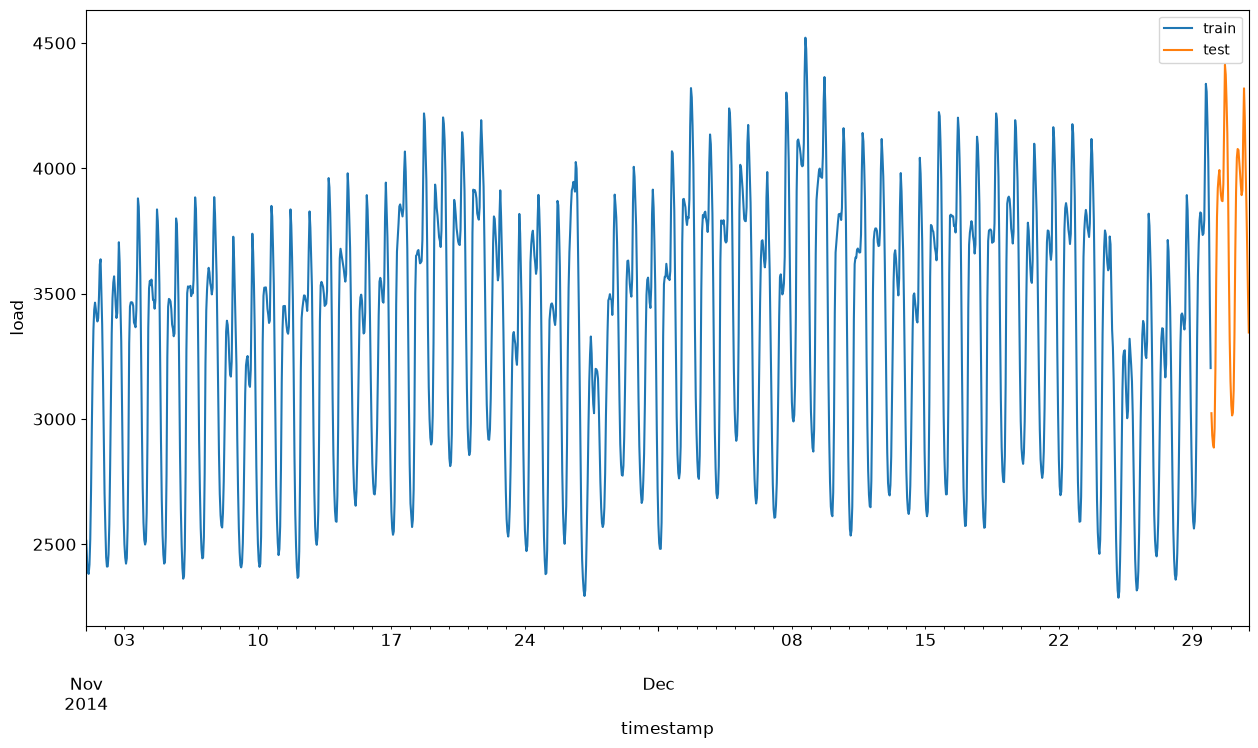

In [22]:
# fmt: off
(
energy[(energy.index >= train_start_dt) & (energy.index < test_start_dt)]
    .rename(columns={'load':'train'}) 
    .join(energy[test_start_dt:].rename(columns={'load':'test'}), how='outer') 
    .plot(y=['train', 'test'], figsize=(15, 8), fontsize=12)
)

plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

<h5 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Prepare the data for training</h5>

Now, you need to prepare the data for training by performing **filtering** and **scaling** of your data.

In [24]:
train = energy.copy()[(energy.index >= train_start_dt) & (energy.index < test_start_dt)][["load"]]
test = energy.copy()[energy.index >= test_start_dt][["load"]]

print("Training data shape: ", train.shape)
print("Test data shape: ", test.shape)

Training data shape:  (1416, 1)
Test data shape:  (48, 1)


Scale the data to be in the range (0, 1).

In [25]:
scaler = MinMaxScaler()
train["load"] = scaler.fit_transform(train)
train.head(5)

,load
2014-11-01 00:00:00,0.101611
2014-11-01 01:00:00,0.065801
2014-11-01 02:00:00,0.046106
2014-11-01 03:00:00,0.042525
2014-11-01 04:00:00,0.059087


In [26]:
test["load"] = scaler.transform(test)
test.head(5)

,load
2014-12-30 00:00:00,0.329454
2014-12-30 01:00:00,0.290063
2014-12-30 02:00:00,0.273948
2014-12-30 03:00:00,0.268129
2014-12-30 04:00:00,0.302596


<h5 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Create Data with Time-Steps</h5>

 For our SVR, we transform the input data to be of the form `[batch, timesteps]`. So, we reshape the existing `train_data` and `test_data` such that there is a new dimension which refers to the timesteps. For our example, we take `timesteps = 5`. So, the inputs to the model are the data for the first 4 timesteps, and the output will be the data for the 5<sup>th</sup> timestep.

In [50]:
# Converting to numpy arrays:
train_data = train.values  # shape=(1416, 1)
test_data = test.values  # shape=(48, 1)

In [51]:
# Selecting the timesteps
timesteps = 5

In [ ]:
# Converting train data to 2D tensor, using nested list comprehension:
# fmt: off
_1412 = len(train_data) - timesteps + 1
train_data_timesteps = (
    np.array([
        [j for j in train_data[i : i + timesteps]] # first slice: train_data[0 : 5]
              for i in range(0, _1412)  # i takes the values 0 to 1412
              ])[:, :, 0]
)
print(train_data_timesteps)
print(train_data_timesteps.shape)

In [ ]:
# Converting test data to 2D tensor
# fmt: off
_44 = len(test_data) - timesteps + 1
test_data_timesteps = (
    np.array([
        [j for j in test_data[i:i+timesteps]]
            for i in range(0,_44)
    ])[:,:,0]
)
print(test_data_timesteps)
print(test_data_timesteps.shape)

Separate the inputs and outputs from the training and testing data:

In [58]:
x_train, y_train = train_data_timesteps[:, : timesteps - 1], train_data_timesteps[:, [timesteps - 1]]
x_test, y_test = test_data_timesteps[:, : timesteps - 1], test_data_timesteps[:, [timesteps - 1]]

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(1412, 4) (1412, 1)
(44, 4) (44, 1)


<h5 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Implement SVR</h5>

1. Define the model using the **RBF kernel**, passing in the model hyperparameters:
    - kernel
    - gamma
    - c
    - epsilon
2. Fit the model to the training data
3. Make predictions using the model

In [59]:
model = SVR(kernel="rbf", gamma=0.5, C=10, epsilon=0.05)
model.fit(x_train, y_train[:, 0])

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.5
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.05
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [64]:
y_train_pred = model.predict(x_train).reshape(-1, 1)
y_test_pred = model.predict(x_test).reshape(-1, 1)

print(y_train_pred.shape, y_test_pred.shape)

(1412, 1) (44, 1)


<h5 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Analyzing Model Performance</h5>

To evaluate the model, first scale back the data to the original scale and then plot the original and predicted time series plot as well as the **MAPE** result.

In [65]:
# Scaling the predictions
y_train_pred = scaler.inverse_transform(y_train_pred)
y_test_pred = scaler.inverse_transform(y_test_pred)

print(len(y_train_pred), len(y_test_pred))

1412 44


In [66]:
# Scaling the original values
y_train = scaler.inverse_transform(y_train)
y_test = scaler.inverse_transform(y_test)

print(len(y_train), len(y_test))

1412 44


Extract the timestamps from the dataset to show in the x-axis of our plot.<br/>
Note that we are using the first `timesteps - 1` values as our input for the first output, so the timestamps for the output will start after that.

In [67]:
train_timestamps = energy[(energy.index >= train_start_dt) & (energy.index < test_start_dt)].index[timesteps - 1 :]
test_timestamps = energy[test_start_dt:].index[timesteps - 1 :]

print(len(train_timestamps), len(test_timestamps))

1412 44


Predictions for training data:

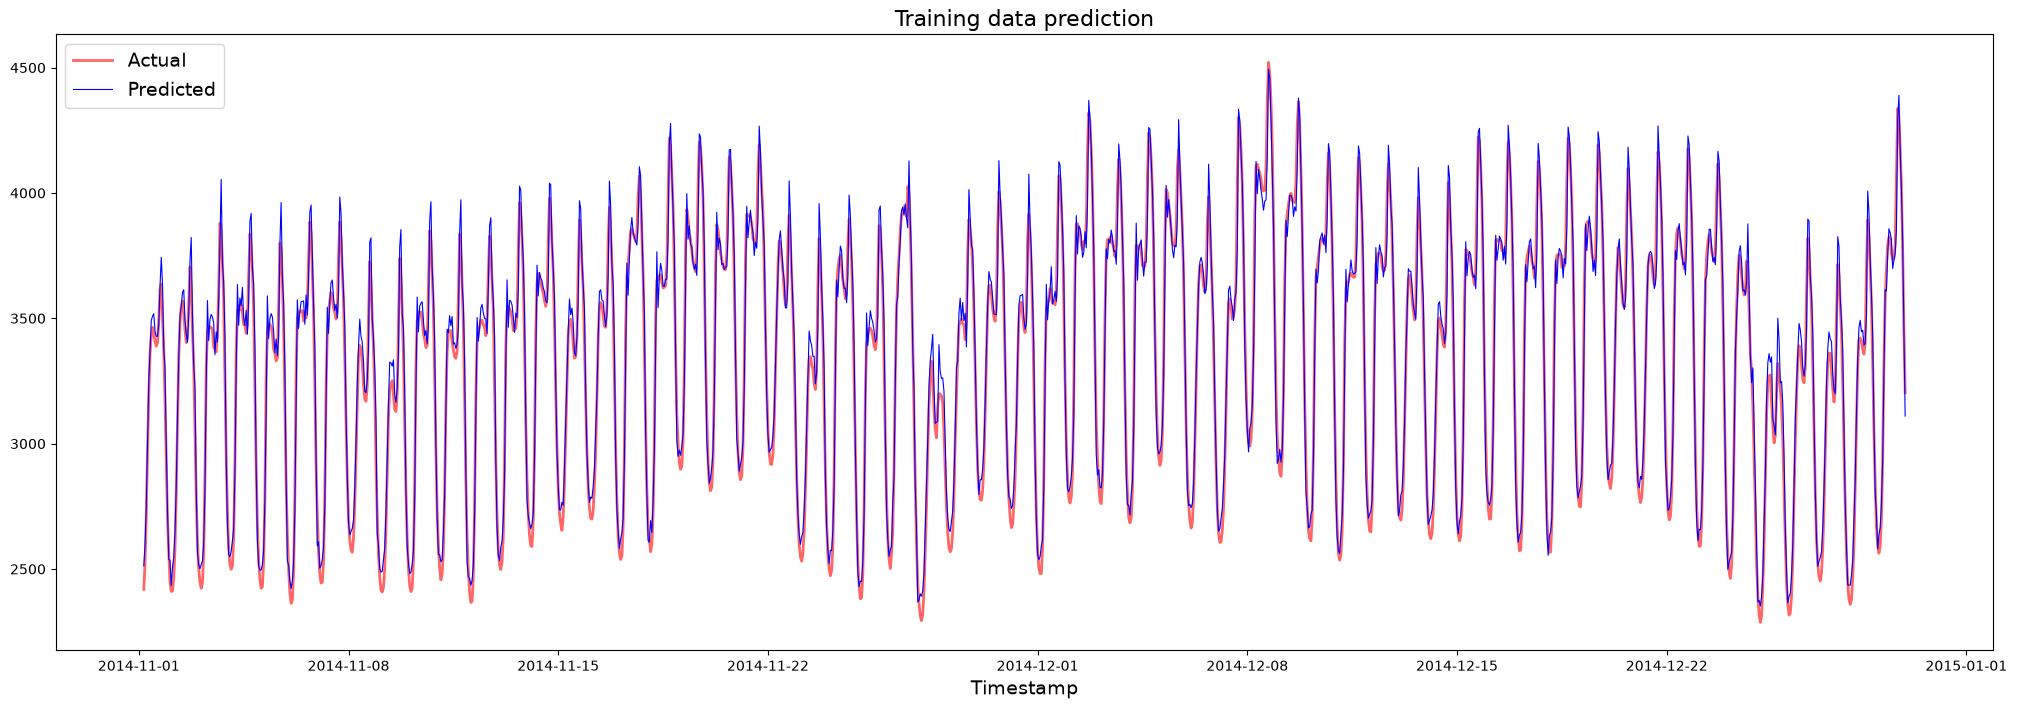

In [75]:
plt.figure(figsize=(25, 8))
plt.plot(train_timestamps, y_train, color="red", linewidth=2.0, alpha=0.6)
plt.plot(train_timestamps, y_train_pred, color="blue", linewidth=0.8)
plt.legend(["Actual", "Predicted"], fontsize=14)
plt.xlabel("Timestamp", fontsize=14)
plt.title("Training data prediction", fontsize=16)
plt.show()

Print MAPE for training data:

In [80]:
print(f"MAPE for training data: {mape(y_train_pred,y_train):.3%}")

MAPE for training data: 1.720%


Plot predictions for training data:

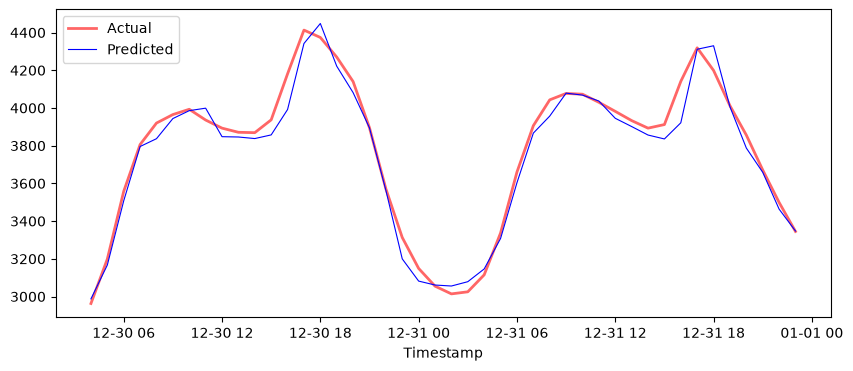

In [82]:
plt.figure(figsize=(10, 4))
plt.plot(test_timestamps, y_test, color="red", linewidth=2.0, alpha=0.6)
plt.plot(test_timestamps, y_test_pred, color="blue", linewidth=0.8)
plt.legend(["Actual", "Predicted"])
plt.xlabel("Timestamp")
plt.show()

In [84]:
print(f"MAPE for testing data: {mape(y_test_pred,y_test):.3%}")

MAPE for testing data: 1.262%


<h5 style="font-weight:600;color:#F0EEE9;background:#295c6b;padding:25px;margin:20;text-align:left;display:fill;border-radius:10px 0 0 10px;text-transform:uppercase;">Check Model Performance on Full Dataset</h5>

In [93]:
# fmt: off
# Extracting load values as numpy array
data = energy.copy().values

# Scaling
data = scaler.transform(data)

# Transforming to 2D tensor as per model input requirement
data_timesteps = np.array([
    [j for j in data[i : i + timesteps]] 
        for i in range(0, len(data) - timesteps + 1)])[:, :, 0]

# Selecting inputs and outputs from data
X, Y = data_timesteps[:, : timesteps - 1], data_timesteps[:, [timesteps - 1]]

print(f"Tensor shape: {data_timesteps.shape}")
print(f"X shape: {X.shape}\nY shape: {Y.shape}")

Tensor shape: (26300, 5)
X shape: (26300, 4)
Y shape: (26300, 1)


In [94]:
# Make model predictions
Y_pred = model.predict(X).reshape(-1, 1)

# Inverse scale and reshape
Y_pred = scaler.inverse_transform(Y_pred)
Y = scaler.inverse_transform(Y)

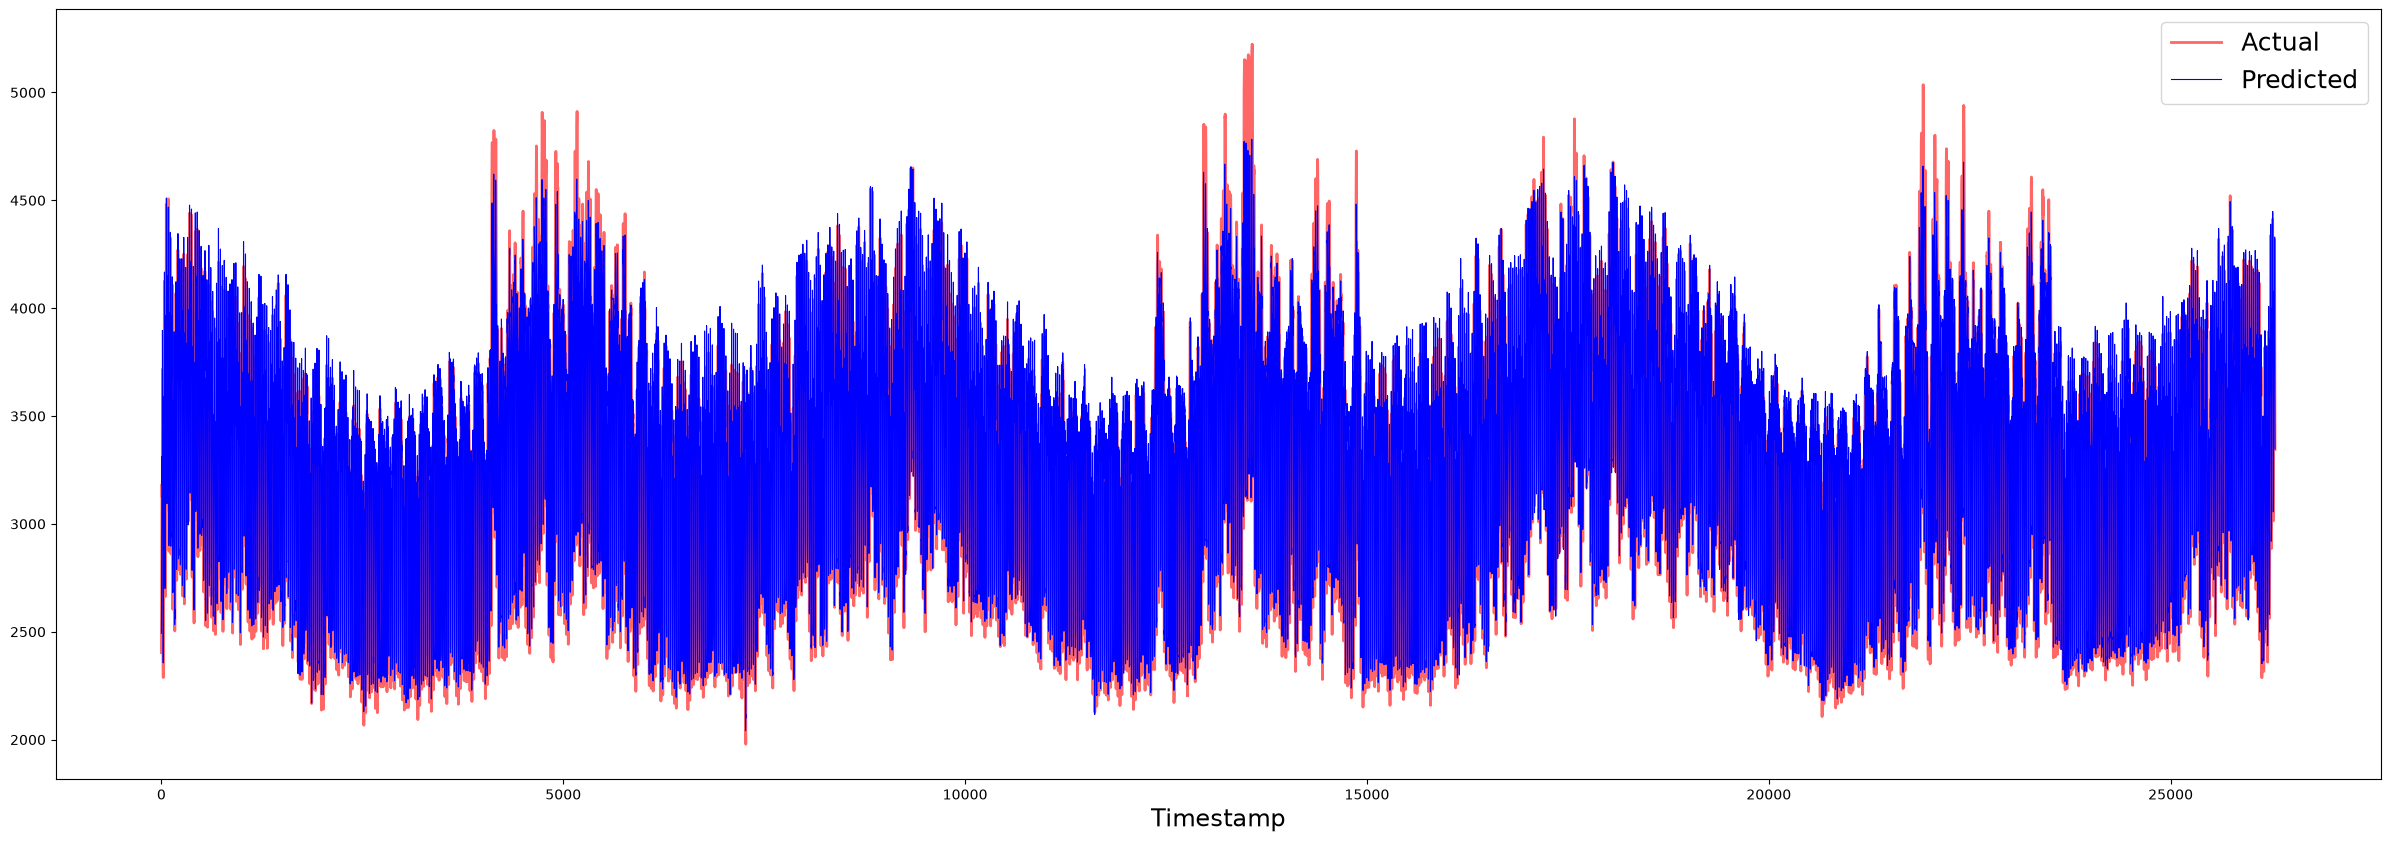

In [101]:
plt.figure(figsize=(30, 10))
plt.plot(Y, color="red", linewidth=2.0, alpha=0.6)
plt.plot(Y_pred, color="blue", linewidth=0.8)
plt.legend(["Actual", "Predicted"], fontsize=18)
plt.xlabel("Timestamp", fontsize=17)
plt.show()

In [102]:
print(f"MAPE: {mape(Y_pred,Y):.3%}")

MAPE: 2.057%


<span style="font-size:1.4rem;font-weight:600;font-style:italic;color:#295c6b;text-decoration:underline;">References:</span>

- [Support Vector Machine (SVM) - Wikipedia](https://en.wikipedia.org/wiki/Support_vector_machine)
- [Support Vector Machine (SVM) - ScikitLearn](https://scikit-learn.org/stable/modules/svm.html)
- [Support Vector Regressor (SVR) - ScikitLearn](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html)
- [SVR Tutorial for Machine Learning](https://www.analyticsvidhya.com/blog/2020/03/support-vector-regression-tutorial-for-machine-learning/)
